In [ ]:
# 목적 : 마케팅 프로젝트 + 데이터 프로젝트 : 고객 & 시장조사 필수 
# 문제인식, 정의, 솔루션, 전략수립, 고객 구체화 
# SNS : 인스타그램, 유튜브 
# 가져온 정보 : 영상컨텐츠, 스탯정보, 댓글정보

In [1]:
import pandas as pd 

df_stats = pd.read_csv("data/youtube_stats_20261104_131559.csv", encoding="utf-8-sig")
df_comments = pd.read_csv("data/youtube_comments_20261104_131559.csv", encoding="utf-8-sig")
df_final = pd.read_csv("data/youtube_final_20261104_131559.csv", encoding="utf-8-sig")

print("영상 데이터:", df_stats.shape) # 찾아온 해당 데이터프레임이 몇행.몇열 (데이터의 크기)
print("댓글 데이터:", df_comments.shape)
print("통합 데이터:", df_final.shape)

영상 데이터: (30, 9)
댓글 데이터: (124, 6)
통합 데이터: (140, 14)


In [7]:
# 데이터 관련 작업 : ctrl + z 안되

videos = df_stats.copy()
comments = df_comments.copy()

comments = comments.dropna(subset=["comment_id","comment"])
comments = comments.drop_duplicates(subset=["comment_id"])

comments["comment"] = comments["comment"].astype(str)

comments["comment_published_at"] = pd.to_datetime(
    comments["comment_published_at"],
    errors="coerce",
    utc=True
).dt.tz_convert("Asia/Seoul")

print("분석 대상 영상:", len(videos))
print("분석 대상 댓글:", len(comments))


분석 대상 영상: 30
분석 대상 댓글: 124


In [4]:
videos.head()

,video_id,title,description,channel,published_at,published_at_Seoul,view_count,like_count,comment_count
0,4x_HqMxIXNQ,# 몬치치 # 젤리 # 말티즈 #베스킨라빈스31,NaN,김쪼꼬미니💕,2026-09-30T13:20:19Z,2026-09-30 22:20:19+09:00,1395,9.0,0.0
1,oA0e4ZqnoSQ,베.라 랜덤 몬치치파우치 사전예약 언방싱! 두구두구 #asmr #cute #베스킨라...,NaN,하울 튜브,2026-09-30T05:49:12Z,2026-09-30 14:49:12+09:00,144,7.0,NaN
2,qPa4NvJMO2Y,배스킨라빈스 31 도쿄바나나 크림브륄레,NaN,민트버터 mint butter,2026-09-29T09:44:48Z,2026-09-29 18:44:48+09:00,271,1.0,0.0
3,iDaiuApfB74,몬치치 랜덤 캡슐깡 #베스킨라빈스31 #몬치치 #몬치치키링 #랜덤캡슐,NaN,유니오니랑 놀자,2026-09-29T08:20:00Z,2026-09-29 17:20:00+09:00,1394,4.0,NaN
4,3lEtUqAqspE,배스킨라빈스에서 캔디도 나온다고? 🍬 #요즘신상 #간식리뷰,NaN,트렌드요정,2026-09-29T03:47:12Z,2026-09-29 12:47:12+09:00,1666,10.0,3.0


In [8]:
comments.info()

# ns : nanosecond = 나노초
# us : microsecond = 마이크로초 
# 동일한 시간을 표기하는데 있어서 : 시간의 정밀도가 ns > us : 1000배 정도 더 정밀한 시간
# 국제표준시 -> 한국시간 : 9시간 (연산 ->마이크로초 소수점 6번째 자리까지, 나노초 9번째 자리까지)

<class 'pandas.DataFrame'>
RangeIndex: 124 entries, 0 to 123
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype                     
---  ------                --------------  -----                     
 0   video_id              124 non-null    str                       
 1   comment_id            124 non-null    str                       
 2   author                124 non-null    str                       
 3   comment               124 non-null    str                       
 4   comment_like_count    124 non-null    int64                     
 5   comment_published_at  124 non-null    datetime64[us, Asia/Seoul]
dtypes: datetime64[us, Asia/Seoul](1), int64(1), str(4)
memory usage: 17.4 KB


In [9]:
videos["like_rate"] = videos["like_count"] / videos["view_count"] * 100
videos["comment_rate"] = videos["comment_count"] / videos["view_count"] * 100
videos["engagement_rate"] = videos["like_count"] + videos["comment_count"] / videos["view_count"] * 100

In [10]:
videos.head()

,video_id,title,description,channel,published_at,published_at_Seoul,view_count,like_count,comment_count,like_rate,comment_rate,engagement_rate
0,4x_HqMxIXNQ,# 몬치치 # 젤리 # 말티즈 #베스킨라빈스31,NaN,김쪼꼬미니💕,2026-09-30T13:20:19Z,2026-09-30 22:20:19+09:00,1395,9.0,0.0,0.645161,0.000000,9.000000
1,oA0e4ZqnoSQ,베.라 랜덤 몬치치파우치 사전예약 언방싱! 두구두구 #asmr #cute #베스킨라...,NaN,하울 튜브,2026-09-30T05:49:12Z,2026-09-30 14:49:12+09:00,144,7.0,NaN,4.861111,NaN,NaN
2,qPa4NvJMO2Y,배스킨라빈스 31 도쿄바나나 크림브륄레,NaN,민트버터 mint butter,2026-09-29T09:44:48Z,2026-09-29 18:44:48+09:00,271,1.0,0.0,0.369004,0.000000,1.000000
3,iDaiuApfB74,몬치치 랜덤 캡슐깡 #베스킨라빈스31 #몬치치 #몬치치키링 #랜덤캡슐,NaN,유니오니랑 놀자,2026-09-29T08:20:00Z,2026-09-29 17:20:00+09:00,1394,4.0,NaN,0.286944,NaN,NaN
4,3lEtUqAqspE,배스킨라빈스에서 캔디도 나온다고? 🍬 #요즘신상 #간식리뷰,NaN,트렌드요정,2026-09-29T03:47:12Z,2026-09-29 12:47:12+09:00,1666,10.0,3.0,0.600240,0.180072,10.180072


In [11]:
# kiwipiepy : 어떤 문장 -> 단어 형태를 추출 -> 해당 단어가 얼만큼 사용
# M/L : 특정 문장 -> 단순히 단어 사용량, 어떤 단어가 대표적인 단어인가, 긍정과 부정의 늬앙스의 단어 분류 가능

%pip install kiwipiepy

     ---------------------------------------- 0.0/87.9 MB ? eta -:--:--
     -------- ----------------------------- 20.2/87.9 MB 109.2 MB/s eta 0:00:01
     ------------------ ------------------- 42.5/87.9 MB 108.5 MB/s eta 0:00:01
     --------------------------- ---------- 64.0/87.9 MB 106.8 MB/s eta 0:00:01
     ------------------------------------ - 84.1/87.9 MB 104.8 MB/s eta 0:00:01
     ---------------------------------------- 87.9/87.9 MB 93.8 MB/s  0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/3.7 MB ? eta -:--:--
   ---------------------------------------- 3.7/3.7 MB 86.0 MB/s  0:00:00
  Created wheel for kiwipiepy_model: filename=kiwipiepy_m

In [15]:
from kiwipiepy import Kiwi

kiwi = Kiwi()

text = "쿠팡플레이에서 재미있는 영상을 시청했습니다."

tokens = kiwi.tokenize(text)

for token in tokens:
    print(token.form, token.tag)

쿠팡 NNP
플레이 NNG
에서 JKB
재미있 VA
는 ETM
영상 NNG
을 JKO
시청 NNG
하 XSV
었 EP
습니다 EF
. SF


- **NNP : Noun Proper : 고유명사 = 서울, 대한민국
- **NNG : Noun General : 일반명사 = 데이터, 마케팅
- JKB : Josa, Kyeok, Busa : 부사격 조사 = 에, 에서
- JKO : Josa, Kyeok, Object : 목적격 조사 = 을, 를 
- **VA : Verb, Adjective: 형용사 : 좋다, 빠르다
- ETM : 연결 어미
- XSV : 명사 파생 접미사
- EP : 선어말 어미 : 었, 겠
- EF : 종결 어미
- SF : 문장 부호

In [17]:
import pandas as pd 
import sys

print("python:", sys.version)
print("pandas:", pd.__version__)

python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
pandas: 3.0.3


In [18]:
# 분석 해야할 대상 : 댓글 분석 =>
# 1) 특정 사이트 및 페이지 URL : http~~~~
# 2) \n, \t, \r 추가
# 3) 특수 문자
# 4) 여백


comments.head()

,video_id,comment_id,author,comment,comment_like_count,comment_published_at
0,3lEtUqAqspE,UgwwO7BEtJ5KIp_IA794AaABAg,@김현정-o7y6l,이클립스랑 살짝 비슷해요?,0,2026-09-29 19:54:44+09:00
1,KPQnbZw3hRY,UgyYPSK_jiSwzkbINM54AaABAg,@뽀얀_67-sixseven,맛있겠어유ㅜㅜㅜ😋,1,2026-09-29 08:04:31+09:00
2,KPQnbZw3hRY,UgwUNoM_nC4nib65fA14AaABAg,@준-q5d,헐 아몬드봉봉 먹어봐야징 1빠요,1,2026-09-28 21:31:46+09:00
3,IlGkeZaDrac,UgyKFruAs0jE3XT89Np4AaABAg,@이창희-z2v,먹고싶당...,0,2026-10-26 17:51:32+09:00
4,IlGkeZaDrac,Ugyq2MgEwM__fVesD_Z4AaABAg,@하이큐-s7e,..아니 편집도 좋고 영퀄도 좋고 먹방도 잘하시는데 왜 안 뜨시는 거지?! 진짜 너...,1,2026-09-28 17:33:14+09:00


In [19]:
# 정규표현식 = regular expression
# r : raw string 약어 -> \s와 같은 문자열 => 원시타입 문자가 존재한다면, 해당 문자열 인정 해석 역할 
# ? : 존재할 수도 있고, 존재하지 않을 수도 있음을 의미
# \S : 공백이 아닌 문자 : non white space 
# \s : 공백인 문자 : white space 
# + : 앞에 입력된 형태의 요소가 1개 이상 반복할 수 있음을 의미
# [] : 문자열 클래스를 생성해서 해당 클래스 안에 겹치는 요소가 1개라도 존재한다면, in[] 
# ^ : [^] : 반대 = 부정, ^[] : ~으로 시작한다는 의미  
# 정제작업을 했다

import re 

def clean_text(text):

    text = str(text)

    text = re.sub(r"https?://\S+", " ", text)

    text = re.sub(r"[\n\r\t]+", " ", text)

    text = re.sub(r"[^가-힣a-zA-Z0-9\s]", " ", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text 

comments["clean_comment"] = comments["comment"].apply(clean_text)
comments[["comment", "clean_comment"]].head(10)

    

,comment,clean_comment
0,이클립스랑 살짝 비슷해요?,이클립스랑 살짝 비슷해요
1,맛있겠어유ㅜㅜㅜ😋,맛있겠어유
2,헐 아몬드봉봉 먹어봐야징 1빠요,헐 아몬드봉봉 먹어봐야징 1빠요
3,먹고싶당...,먹고싶당
4,..아니 편집도 좋고 영퀄도 좋고 먹방도 잘하시는데 왜 안 뜨시는 거지?! 진짜 너...,아니 편집도 좋고 영퀄도 좋고 먹방도 잘하시는데 왜 안 뜨시는 거지 진짜 너무 맛있...
5,역시 남뚜 클라수 ㄷㄷ,역시 남뚜 클라수
6,지나가면서 맥날 광고 할수있음 ㅋㅋ🎉,지나가면서 맥날 광고 할수있음
7,맛있게다.,맛있게다
8,에그타르트로 만들면 훨 나을거 같아요! 숟가락은 초콜릿숟가락에 팡크 추가해서 아예 ...,에그타르트로 만들면 훨 나을거 같아요 숟가락은 초콜릿숟가락에 팡크 추가해서 아예 대...
9,색 완전 잘나왔어요 근데 숟가락ㅜㅜ 다음 기회에…,색 완전 잘나왔어요 근데 숟가락 다음 기회에


In [21]:
def extract_nouns(text):

    tokens = kiwi.tokenize(text) 
    
    # 리스트라는 자료구조 안에서 for in 사용, 반복문을 통해서 추출된 값들을 바로 리스크화 = 리스트 컴프리핸션
    nouns = [token.form for token in tokens if token.tag in ["NNG", "NNP"] and len(token.form) >= 2]

    return nouns

comments["nouns"] = comments["clean_comment"].apply(extract_nouns)

pd.set_option("display.max_rows", None) 

comments[["clean_comment", "nouns"]] 

,clean_comment,nouns
0,이클립스랑 살짝 비슷해요,[이클립스랑]
1,맛있겠어유,[]
2,헐 아몬드봉봉 먹어봐야징 1빠요,[아몬드]
3,먹고싶당,[]
4,아니 편집도 좋고 영퀄도 좋고 먹방도 잘하시는데 왜 안 뜨시는 거지 진짜 너무 맛있...,"[편집, 먹방]"
5,역시 남뚜 클라수,[클라수]
6,지나가면서 맥날 광고 할수있음,"[맥날, 광고]"
7,맛있게다,[]
8,에그타르트로 만들면 훨 나을거 같아요 숟가락은 초콜릿숟가락에 팡크 추가해서 아예 대...,"[에그타르트, 숟가락, 초콜릿, 숟가락, 팡크, 추가, 대왕, 추천]"
9,색 완전 잘나왔어요 근데 숟가락 다음 기회에,"[숟가락, 다음, 기회]"


In [22]:
# 키위 -> 문장 -> 명사 추출 -> 특정 불필요한 단어, 키워드 배제 

# 불용어 = stopword

stopwords = {
    "지랄", "워리워", "개미쳤놐", "노릇", "도데체"
    
}

def remove_stopwords(words):

    return [word for word in words if word not in stopwords]

comments["filtered_nouns"] = comments["nouns"].apply(remove_stopwords)

comments

,video_id,comment_id,author,comment,comment_like_count,comment_published_at,clean_comment,nouns,filtered_nouns
0,3lEtUqAqspE,UgwwO7BEtJ5KIp_IA794AaABAg,@김현정-o7y6l,이클립스랑 살짝 비슷해요?,0,2026-09-29 19:54:44+09:00,이클립스랑 살짝 비슷해요,[이클립스랑],[이클립스랑]
1,KPQnbZw3hRY,UgyYPSK_jiSwzkbINM54AaABAg,@뽀얀_67-sixseven,맛있겠어유ㅜㅜㅜ😋,1,2026-09-29 08:04:31+09:00,맛있겠어유,[],[]
2,KPQnbZw3hRY,UgwUNoM_nC4nib65fA14AaABAg,@준-q5d,헐 아몬드봉봉 먹어봐야징 1빠요,1,2026-09-28 21:31:46+09:00,헐 아몬드봉봉 먹어봐야징 1빠요,[아몬드],[아몬드]
3,IlGkeZaDrac,UgyKFruAs0jE3XT89Np4AaABAg,@이창희-z2v,먹고싶당...,0,2026-10-26 17:51:32+09:00,먹고싶당,[],[]
4,IlGkeZaDrac,Ugyq2MgEwM__fVesD_Z4AaABAg,@하이큐-s7e,..아니 편집도 좋고 영퀄도 좋고 먹방도 잘하시는데 왜 안 뜨시는 거지?! 진짜 너...,1,2026-09-28 17:33:14+09:00,아니 편집도 좋고 영퀄도 좋고 먹방도 잘하시는데 왜 안 뜨시는 거지 진짜 너무 맛있...,"[편집, 먹방]","[편집, 먹방]"
5,7pjP8PzUt0A,UgxyJ4i5ylDpZ5UH-NB4AaABAg,@남희장-m8s,역시 남뚜 클라수 ㄷㄷ,1,2026-09-30 19:30:07+09:00,역시 남뚜 클라수,[클라수],[클라수]
6,7pjP8PzUt0A,Ugw0dP_Wy4R_SKgkC3B4AaABAg,@슬아-f8m,지나가면서 맥날 광고 할수있음 ㅋㅋ🎉,1,2026-09-28 20:21:06+09:00,지나가면서 맥날 광고 할수있음,"[맥날, 광고]","[맥날, 광고]"
7,7pjP8PzUt0A,Ugyc4F3SSG_MHpoDSoB4AaABAg,@설콩이-OuO,맛있게다.,2,2026-09-27 22:57:29+09:00,맛있게다,[],[]
8,7pjP8PzUt0A,Ugw-Aejj_KTcNLY4hXt4AaABAg,@뀨-k1m,에그타르트로 만들면 훨 나을거 같아요! 숟가락은 초콜릿숟가락에 팡크 추가해서 아예 ...,4,2026-09-27 22:44:17+09:00,에그타르트로 만들면 훨 나을거 같아요 숟가락은 초콜릿숟가락에 팡크 추가해서 아예 대...,"[에그타르트, 숟가락, 초콜릿, 숟가락, 팡크, 추가, 대왕, 추천]","[에그타르트, 숟가락, 초콜릿, 숟가락, 팡크, 추가, 대왕, 추천]"
9,7pjP8PzUt0A,UgzAVvbWAtUytFLjMXt4AaABAg,@집가고싶다_뤂,색 완전 잘나왔어요 근데 숟가락ㅜㅜ 다음 기회에…,1,2026-09-27 21:34:49+09:00,색 완전 잘나왔어요 근데 숟가락 다음 기회에,"[숟가락, 다음, 기회]","[숟가락, 다음, 기회]"


In [26]:
from collections import Counter

all_words = [word for words in comments["filtered_nouns"] for word in words]

word_counts = Counter(all_words)

df_words = pd.DataFrame(
    word_counts.most_common(30),
    columns=["word", "frequency"]
)
df_words

,word,frequency
0,언니,8
1,마카롱,6
2,숟가락,5
3,댓글,5
4,먹방,4
5,크림브륄레,4
6,다음,3
7,최고,3
8,인형,3
9,베라,3


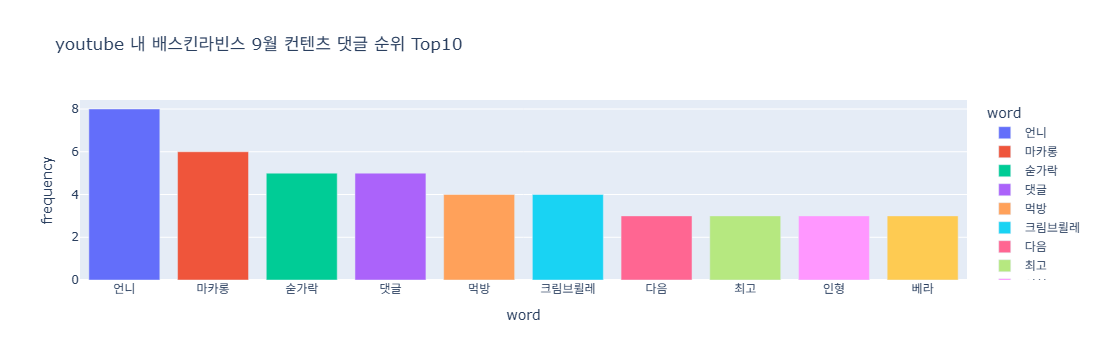

In [33]:
import plotly.express as px

top10 = df_words.head(10).sort_values("frequency", ascending=False)

fig = px.bar(
    top10,
    x="word",
    y="frequency",
    title="youtube 내 배스킨라빈스 9월 컨텐츠 댓글 순위 Top10",
    color="word"
)

fig.show()